# BIOT 6900 · Module 9 — Notebook 3 (GRADED)
## Clinical NLP on your own disease: build it, then catch the leakage
**Week 9 · Part III · this is the graded assignment**

> **⚠️ SYNTHETIC.** You design a synthetic patient population for a disease of your choice, run the full pipeline on it, and then do the hard part: look at what the model learned and separate genuine early signal from leakage.

You configure your disease's clinical picture (which findings are genuine early signals, which are interventions done to deteriorating patients). The notebook builds a cohort and notes from your choices, extracts features, trains a model, and reports permutation importance. **It also injects two clinical features you did not configure** — you must diagnose each as signal or leakage from the output.

**What is graded (course 60 / 40):** 60% execution (your config is clinically sensible, the notebook runs, the pipeline is correct) and **40% interpretation** (Part D: correctly sorting signal from leakage and defending it). See the assignment sheet for the rubric.

**How to run:** `Kernel → Restart & Run All`. It uses only `pandas` + `scikit-learn`.

## The engine (provided, do not edit)
Run this cell and move on. It defines the assertion engine, the cohort/notes generator, and the model helpers.

In [1]:
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# --- ConText assertion engine (from Notebook 2) ---
NEG_PRE  = ["no evidence of", "no acute", "denies", "denied", "without", "negative for", "ruled out for", "r/o", "no "]
NEG_POST = ["ruled out", "was negative", "is negative", "unlikely", "resolved"]
PSEUDO   = ["no change", "no increase", "no further", "not only", "cannot be ruled out", "gram negative"]
FAM      = ["mother", "father", "sister", "brother", "parent", "family history", "fh "]
HIST     = ["history of", "h/o", "hx of", "prior", "previous", "status post", "s/p", "chronic"]
HYPO     = ["if ", "would ", "should ", "to prevent", "risk of", "monitor for"]
def _sents(t): return [s.strip() for s in re.split(r"[.;\n]", t) if s.strip()]
def assertion(term, text):
    for sent in _sents(text):
        low = sent.lower()
        m = re.search(r"\b" + re.escape(term.lower()) + r"\b", low)
        if not m: continue
        pos = m.start(); pseudo = any(p in low for p in PSEUDO)
        pre = low[max(0, pos-60):pos]; post = low[pos+len(term):pos+len(term)+45]
        if any(x in low for x in FAM): return "family"
        if any(x in pre for x in HYPO): return "hypothetical"
        if not pseudo and (any(x in pre for x in NEG_PRE) or any(x in post for x in NEG_POST)): return "absent"
        if any(x in pre for x in HIST): return "historical"
        return "present"
    return None

def concept_present(synonyms, note_texts):
    for v in synonyms:
        for t in note_texts:
            if assertion(v, t) == "present":
                return 1
    return 0

# two features injected that you did NOT configure (diagnose them in Part D):
WILDCARDS = {
    "lactate_not_clearing": ["failing to clear", "not clearing"],
    "renal_replacement":    ["dialysis", "renal replacement therapy"],
}

def build_world(cfg, seed=2024, N=400):
    rng = np.random.default_rng(seed)
    age = rng.integers(40, 92, N); sex = rng.choice(["M", "F"], N)
    lactate = rng.normal(2.2, 1.3, N).clip(0.5, 14); creatinine = rng.normal(1.1, 0.6, N).clip(0.3, 9)
    sig_names = list(cfg["signals"]); con_names = list(cfg["consequences"])
    sig_present = {s: rng.random(N) < rng.uniform(0.18, 0.30) for s in sig_names}
    w_sig = rng.random(N) < 0.22                               # wildcard SIGNAL (a cause)
    logit = -2.3 + 0.045*(age-65) + 0.55*(lactate-2) + 0.3*(creatinine-1) + 0.55*w_sig
    for s in sig_names: logit = logit + 0.6*sig_present[s]
    died = (rng.random(N) < 1/(1+np.exp(-logit))).astype(int)
    w_leak = ((died == 1) & (rng.random(N) < 0.5)) | ((died == 0) & (rng.random(N) < 0.10))  # wildcard LEAK

    def notes_for(i):
        adm = [f"{age[i]}{sex[i]} admitted to the ICU.", f"Lactate {lactate[i]:.1f}, creatinine {creatinine[i]:.1f}."]
        for s in sig_names:
            syns = cfg["signals"][s]
            if sig_present[s][i]: adm.append(f"Clinical note: {rng.choice(syns)} present.")
            elif rng.random() < 0.25: adm.append(f"No evidence of {syns[0]}.")
        if w_sig[i]: adm.append("Lactate failing to clear despite resuscitation.")
        if rng.random() < 0.2: adm.append("History of MI, no acute chest pain.")
        prog = ["Progress note, hospital day 2."]
        if rng.random() < 0.15: prog.append("Family history of diabetes.")
        disch = ["Discharge / final note."]
        if died[i]:
            for c in con_names:
                if rng.random() < 0.5: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Required renal replacement therapy (dialysis).")
        else:
            for c in con_names:
                if rng.random() < 0.10: disch.append(f"{rng.choice(cfg['consequences'][c]).capitalize()}.")
            if w_leak[i]: disch.append("Brief dialysis for contrast, since stopped.")
            disch.append(rng.choice(["Tolerating diet, ambulating.", "Stable for discharge."]))
        return [" ".join(adm), " ".join(prog), " ".join(disch)]

    NOTES = [notes_for(i) for i in range(N)]
    struct = pd.DataFrame({"subject_id": np.arange(1, N+1), "age": age, "sex": sex,
                           "lactate": lactate.round(1), "creatinine": creatinine.round(1), "died": died})
    struct.loc[rng.random(N) < 0.15, "lactate"] = np.nan
    return struct, NOTES

def cv_auroc(df, cols):
    X, y = df[cols].values, df["died"].values
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
    s = cross_val_score(pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    return s.mean(), s.std()

def perm_importance(df, cols):
    X, y = df[cols].values, df["died"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
    pi = permutation_importance(pipe, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=0)
    return pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)

print("engine loaded.")

engine loaded.


## Part A — Configure your disease  (TODO)
Replace the EXAMPLE config with **your own disease**. You need:
- 2–3 **signals**: genuine, *early* findings that are **causes** of deterioration (present before things go wrong).
- 2–3 **consequences**: interventions or actions taken *because* a patient is deteriorating. These are your planted leakage.
- For each, give a few **synonyms / abbreviations** (the notes will use them at random, so normalization matters).

Choosing these well is a clinical-reasoning task, and it is graded. A cause belongs in `signals`; a treatment or end-of-life decision belongs in `consequences`.

In [2]:
# ======== EDIT THIS: replace the example with YOUR disease ========
CONFIG = {
    "disease": "Community-acquired pneumonia (CAP), adult inpatients",
    "signals": {                                              # genuine EARLY signals
        "confusion": ["confused", "altered mental status", "AMS", "disoriented", "new confusion"],
        "tachypnea": ["tachypneic", "fast breathing", "RR elevated", "respiratory rate high", "increased work of breathing"],
        "hypoxia":   ["hypoxic", "low SpO2", "low sats on room air", "desaturating", "low oxygen saturation"],
    },
    "consequences": {                                         # interventions on deteriorating patients (LEAKAGE)
        "intubation":   ["intubated", "mechanical ventilation", "ventilated", "ETT placed", "on the vent"],
        "vasopressors": ["norepinephrine", "levophed", "pressors", "started on pressors", "vasopressor support"],
        "comfort_care": ["comfort measures", "DNR", "transitioned to comfort care", "palliative care consult", "goals of care changed to comfort"],
    },
}

SEED = 2088061       # ID 002088061, leading zeros dropped for Python
# =================================================================

# Why each concept is where it is:
# confusion (signal): new confusion comes from the infection itself, is seen at the first exam, and is the C in CURB-65.
# tachypnea (signal): fast breathing is the patient's own response to the lung infection and is an early CURB-65 / SMART-COP / ATS-IDSA minor criterion.
# hypoxia (signal): low SpO2 on room air is the patient's own physiology before any oxygen is given, and poor oxygenation is in SMART-COP and ATS-IDSA.
#   (oxygen given to keep sats up is a treatment, and high-flow / BiPAP is escalation, so neither is a hypoxia synonym.)
# intubation (consequence): the team intubates because the patient is already in respiratory failure; it is an ATS-IDSA major criterion.
# vasopressors (consequence): pressors are started because the patient is already in septic shock; also an ATS-IDSA major criterion.
# comfort_care (consequence): comfort care / DNR is an end-of-life decision made once the team expects a bad outcome.

struct, NOTES = build_world(CONFIG, seed=SEED, N=400)
print("#"*70)
print(f"# SYNTHETIC cohort for: {CONFIG['disease']}")
print(f"# 400 patients, 3 notes each. Mortality prevalence = {struct.died.mean():.2f}")
print("#"*70)
print("Example patient notes:")
for tag, t in zip(["admit ", "day 2 ", "final "], NOTES[0]):
    print(f"  [{tag}] {t}")

######################################################################
# SYNTHETIC cohort for: Community-acquired pneumonia (CAP), adult inpatients
# 400 patients, 3 notes each. Mortality prevalence = 0.26
######################################################################
Example patient notes:
  [admit ] 78M admitted to the ICU. Lactate 1.0, creatinine 1.5.
  [day 2 ] Progress note, hospital day 2.
  [final ] Discharge / final note. Stable for discharge.


## Part B — Extract features  (TODO)
Assemble every concept to extract: your signals, your consequences, and the two injected wildcards. Then run the extractor across all 400 patients.

In [3]:
# the two injected features you did NOT configure are added here for you:
ALL_CONCEPTS = {**CONFIG["signals"], **CONFIG["consequences"], **WILDCARDS}

feat = pd.DataFrame({"subject_id": struct.subject_id})
for name, syns in ALL_CONCEPTS.items():
    feat[name] = [concept_present(syns, NOTES[i]) for i in range(400)]

print("Patients with each concept asserted PRESENT:")
print(feat.drop(columns="subject_id").sum().to_string())

Patients with each concept asserted PRESENT:
confusion               103
tachypnea               130
hypoxia                 112
intubation               85
vasopressors             77
comfort_care             79
lactate_not_clearing     97
renal_replacement        85


Sanity check: compare naive keyword counting to assertion-aware counting for one of your signals.

In [4]:
one_signal = list(CONFIG["signals"])[0]
syns = CONFIG["signals"][one_signal]
naive = sum(int(any(re.search(r"\b"+re.escape(v)+r"\b", " ".join(NOTES[i]), re.I) for v in syns)) for i in range(400))
aware = int(feat[one_signal].sum())
print(f"{one_signal}:  naive keyword count = {naive}   assertion-aware = {aware}")

confusion:  naive keyword count = 186   assertion-aware = 103


**Extraction check.** No feature is at 0 or 400. All three signals (103–130 patients) are more common than all three consequences (77–85), which fits CAP, where most patients are not intubated or on pressors.

For confusion, the naive keyword count is 186 and the assertion-aware count is 103. The naive method over-counts by 83 because it picks up negated lines like "No evidence of confused", which are patients who did NOT have the finding.

## Part C — Model and importance  (TODO)
Build the feature matrix, then **declare which of YOUR concepts you planted as leakage**. Do not include the wildcards yet — you have to find those in Part D.

In [5]:
df = struct.merge(feat, on="subject_id")
df["sex_F"] = (df.sex == "F").astype(int)
struct_cols = ["age", "sex_F", "lactate", "creatinine"]
concept_cols = list(ALL_CONCEPTS)
all_cols = struct_cols + concept_cols

# TODO: list the concepts YOU configured as consequences (your planted leakage)
declared_leak = ["intubation", "vasopressors", "comfort_care"]     # my configured consequences; wildcards not included yet

m, sd   = cv_auroc(df, all_cols)
mh, sdh = cv_auroc(df, [c for c in all_cols if c not in declared_leak])
print(f"CV AUROC   all features = {m:.3f} ± {sd:.3f}")
print(f"CV AUROC   your declared leakage removed = {mh:.3f} ± {sdh:.3f}")

CV AUROC   all features = 0.891 ± 0.044
CV AUROC   your declared leakage removed = 0.786 ± 0.032


comfort_care            0.070
vasopressors            0.056
renal_replacement       0.038
intubation              0.037
lactate                 0.030
age                     0.028
confusion               0.017
hypoxia                 0.009
lactate_not_clearing    0.002
creatinine             -0.000
sex_F                  -0.002
tachypnea              -0.004


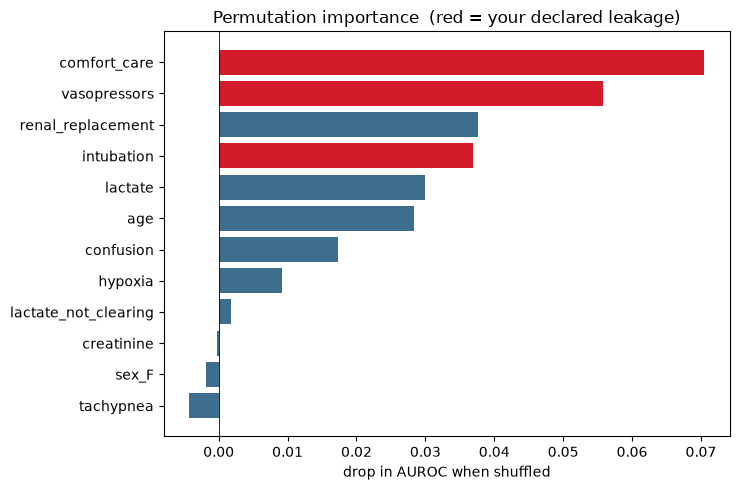

In [6]:
imp = perm_importance(df, all_cols)
print(imp.round(3).to_string())

order = imp.sort_values()
leakset = set(declared_leak)
colors = ["#D41B2C" if c in leakset else "#3E6E8E" for c in order.index]
plt.figure(figsize=(7.5, 5))
plt.barh(order.index, order.values, color=colors)
plt.axvline(0, color="black", linewidth=0.6)
plt.title("Permutation importance  (red = your declared leakage)")
plt.xlabel("drop in AUROC when shuffled"); plt.tight_layout(); plt.show()

## Part D — Catch the leakage and interpret  (GRADED, the 40%)
Now the real work. Answer each prompt in the markdown cell that follows it. Use the permutation importance and the AUROC numbers as evidence, and clinical reasoning (cause vs consequence) as the argument.

### D1. Read the importance plot
List the features at the **top** of the permutation-importance ranking. For each, say whether it is genuine early **signal** or **leakage**, and give a one-sentence clinical reason (is it a cause the patient had, or a consequence of them deteriorating?).

**Answer:**

These are the top 8 of the 12 features, by drop in AUROC when shuffled:

| Rank | Feature | Importance | Call | Reason |
|---|---|---|---|---|
| 1 | comfort_care | 0.070 | Leakage | The team decides on comfort care or DNR once they already expect the patient to die. |
| 2 | vasopressors | 0.056 | Leakage | Pressors are started because the patient is already in septic shock. |
| 3 | renal_replacement | 0.038 | Leakage | New dialysis is a step up in care for kidneys that are already failing (see D2). |
| 4 | intubation | 0.037 | Leakage | The team intubates because the patient is already in respiratory failure. |
| 5 | lactate | 0.030 | Signal | Admission lactate is an early lab that shows how sick the patient is when they arrive. |
| 6 | age | 0.028 | Signal (baseline risk) | Age is known before admission. It raises risk but is a risk factor, not a finding of the infection. |
| 7 | confusion | 0.017 | Signal | New confusion is found at the first exam and is an early sign of severe CAP (the C in CURB-65). |
| 8 | hypoxia | 0.009 | Signal | Low SpO2 on room air is the patient's own physiology before oxygen is given. |

The four features at the top are all leakage. They are records of the team reacting to a patient who was already getting worse. The model is mostly learning what the team did, not what the patient had. Tachypnea came last (−0.004). The engine gives all three signals the same weight, so I think this is noise from a small test set (120 patients, 31 deaths), not a real lack of signal.

### D2. Hunt the hidden leak
Your 'declared leakage removed' AUROC is probably still high. That is a clue you missed a leak. Two features were injected that you did not configure: **`lactate_not_clearing`** and **`renal_replacement`**. From the importance plot and clinical reasoning, classify each as signal or leakage, and justify. Then add any you judge to be leakage to the set below and re-run.

**Answer:**

**renal_replacement: leakage.** Dialysis is something the team does, not something the patient has. In this cohort it only shows up in the discharge/final note ("Required renal replacement therapy", "Brief dialysis for contrast, since stopped"). That means it was started during the stay, after admission. It is new acute dialysis, not chronic dialysis. Chronic dialysis would be a baseline comorbidity, and the engine would mark it as "historical" because of the word "chronic". New dialysis in CAP is an escalation for acute kidney injury in a patient who is already failing, the same kind of step as pressors or intubation. The numbers agree. It ranks 3rd in importance (0.038), above intubation. It is present in 46% of patients who died and 13% of survivors. Removing it drops AUROC from 0.786 to 0.720.

**lactate_not_clearing: signal, but a late one.** This is a lab result, so it measures the patient's physiology, not a decision by the team. Its timing is not as early as confusion or tachypnea, though. "Not clearing" means lactate was checked again after fluids and antibiotics had started, so it can only exist once treatment is under way. I still call it a signal. It tells you the patient is not responding while there is still time to act, and it sits in the admission note here, before any escalation. It also does not behave like a leak. It ranks 9th of 12 (0.002) and is not in the top 6 of the honest model. If it were leakage it would sit near the top with the other leak features. Removing it from the honest model leaves AUROC at 0.720, the same as with it, so the model was not leaning on it the way it leaned on the leak features.

So I set `final_leak = declared_leak + ["renal_replacement"]` and kept lactate_not_clearing in the model.

Honest-model importance (all leakage removed, top 6):

| Feature | Importance |
|---|---|
| age | 0.109 |
| lactate | 0.084 |
| hypoxia | 0.050 |
| confusion | 0.014 |
| tachypnea | 0.012 |
| sex_F | 0.004 |

In [7]:
# TODO: your FINAL leak set = your declared leakage + any wildcard you caught
final_leak = declared_leak + ["renal_replacement"]     # D2: renal_replacement = leakage (new dialysis is an escalation); lactate_not_clearing kept as signal

m_all, _    = cv_auroc(df, all_cols)
m_honest, _ = cv_auroc(df, [c for c in all_cols if c not in final_leak])
print(f"AUROC with everything     = {m_all:.3f}")
print(f"AUROC, all leakage removed = {m_honest:.3f}")
print(f"AUROC, all leakage removed, also without lactate_not_clearing = {cv_auroc(df, [c for c in all_cols if c not in final_leak + ['lactate_not_clearing']])[0]:.3f}")

# does a wildcard you kept as signal actually matter once leakage is gone?
honest_imp = perm_importance(df, [c for c in all_cols if c not in final_leak])
print("\nHonest-model importance (top 6):")
print(honest_imp.head(6).round(3).to_string())

AUROC with everything     = 0.891
AUROC, all leakage removed = 0.720
AUROC, all leakage removed, also without lactate_not_clearing = 0.720



Honest-model importance (top 6):
age          0.109
lactate      0.084
hypoxia      0.050
confusion    0.014
tachypnea    0.012
sex_F        0.004


### D3. Quantify the damage
Report the AUROC with everything, with your declared leakage removed, and with all leakage removed (including any wildcard you caught). What does the size of each drop tell you about how much of the model's apparent skill was leakage?

**Answer:**

| Feature set | CV AUROC |
|---|---|
| All features | 0.891 ± 0.044 |
| Declared leakage removed (intubation, vasopressors, comfort_care) | 0.786 ± 0.032 |
| All leakage removed (final_leak, adds renal_replacement) | 0.720 ± 0.060 |

**First drop (0.891 → 0.786).** Skill above chance (AUROC − 0.5) goes from 0.391 to 0.286. So about 27% of the apparent skill came from the three consequences I planted. The model was using the team's response to deterioration to "predict" the deterioration.

**Second drop (0.786 → 0.720).** Removing the planted leaks was not enough. renal_replacement was a hidden leak, and removing it took skill above chance down to 0.220. That is another 0.066, about 17% of the original skill.

**Final number (0.720).** In total 0.171 of 0.391, about 44% of the apparent skill, was leakage. What is left is a moderate model on early information only: age, admission lactate, hypoxia, confusion and tachypnea. The wider SD (±0.060) means it is less stable across folds.

### D4. Reality check
Pick your two strongest genuine signals. Would they actually be **documented early enough** to act on in a real chart? Name one way this synthetic cohort is unlike real clinical data (think about the lecture's documentation-bias and small-cohort points).

**Answer:**

In the honest model, age and admission lactate rank above my configured signals. I left out age because it is a baseline risk factor, not something you can act on. I left out lactate because it is a structured lab, not one of my note-based signals. Of my configured signals, hypoxia and confusion are the strongest.

My two strongest genuine signals in the honest model are hypoxia (0.050) and confusion (0.014). Yes, both would normally be documented early. SpO2 and respiratory rate are taken at triage with the first set of vitals. Mental status is checked in the first ED exam and is part of CURB-65, which is often scored on admission. The catch is that SpO2 on room air is only recorded before oxygen goes on. After that, notes record "sats 94% on 2L", and that is a treatment, not a signal. Confusion is also often written only in free text, not in a structured field.

**One way this cohort is unlike real data: timing is perfect, and it is assumed, not recorded.** The generator always writes signals into the admission note and consequences into the discharge note. That fixed order is the only reason I can tell signal from leak here. The model itself ignores timing. The extractor reads all three notes for each patient, including the discharge note, and that is how the leak features got in. Real charts are messier. A note's time is when it was written, not when the event happened, and copy-forward repeats lines like "intubated, on levophed" into later notes. To keep leakage out of a real model, I would only use notes written before a fixed prediction time (for example, the first 24 hours after admission). That only works if the timestamps can be trusted.

## What to submit
- This notebook, run top to bottom (`Kernel → Restart & Run All`), committed to your biot6900 repo.
- Your written answers to D1–D4 in the markdown cells above.
- A short README noting your disease and anything that did not work.

Then post your repo link on Canvas. Grading follows the assignment sheet (course 60 / 40).